# Projeto: Análise de Dados de Videogames (Loja Ice)

## Etapa 1. Abra o arquivo de dados e estude as informações gerais

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('games.csv')

print("Primeiras linhas do DataFrame:")
display(df.head())

print("\nInformações gerais dos dados:")
df.info()

Primeiras linhas do DataFrame:


,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN



Informações gerais dos dados:
<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  str    
 1   Platform         16715 non-null  str    
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  str    
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  str    
 10  Rating           9949 non-null   str    
dtypes: float64(6), str(5)
memory usage: 2.0 MB


## Etapa 2. Prepare os dados

In [2]:
df.columns = df.columns.str.lower()
print("Novos nomes das colunas:")
print(df.columns)

Novos nomes das colunas:
Index(['name', 'platform', 'year_of_release', 'genre', 'na_sales', 'eu_sales',
       'jp_sales', 'other_sales', 'critic_score', 'user_score', 'rating'],
      dtype='str')


In [3]:
df['year_of_release'] = df['year_of_release'].astype('Int64')
df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')
print("\nNovos tipos de dados:")
df.info()


Novos tipos de dados:
<class 'pandas.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  str    
 1   platform         16715 non-null  str    
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  str    
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   str    
dtypes: Int64(1), float64(6), str(4)
memory usage: 2.0 MB


year_of_release foi alterado de float64 para Int64 pois ambos são valores inteiros por natureza. O tipo Int64 foi utilizado porque permite manter a coluna como inteira mesmo contendo valores nulos (NaN).  
Já user_score foi alterado de object para float64 pois notas são valores decimais usados para cálculos (médias, medianas). A coluna estava como texto devido ao termo 'tbd' (a ser determinado), que foi convertido em valor nulo através do pd.to_numeric() com errors='coerce'.

In [4]:
df['rating'] = df['rating'].fillna('Unknown')
df = df.dropna(subset=['name', 'genre'])

print("Valores ausentes restantes por coluna:")
print(df.isnull().sum())

Valores ausentes restantes por coluna:
name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating                0
dtype: int64


Abordagem para Valores Ausentes:  
name e genre: Linhas nulas foram eliminadas. Como são informações vitais e a quantidade era insignificante, a remoção não impacta o resultado final.  
year_of_release: Mantidos como nulos. Preencher com média ou mediana poderia atribuir jogos a gerações erradas de consoles, distorcendo a análise temporal.  
critic_score e user_score: Mantidos como nulos. Inserir notas artificiais (como zero ou a média) geraria um viés, prejudicando a análise de correlação entre avaliações e vendas.  
rating (ESRB): Substituídos por 'Unknown'. Essa categoria é essencial para incluir os jogos sem classificação na análise de impacto de vendas por região, evitando a perda desses dados.

Motivos para a Ausência de Dados:  
Dados recém-criados: Jogos adicionados à base muito próximos da data de extração dos dados podem não ter tido tempo hábil para acumular avaliações dos usuários.  
Erros de digitação ou input manual: Falha humana no cadastro original, onde o operador esqueceu ou pulou o preenchimento de campos como ano ou classificação por descuido ou pressa.  
Falhas na extração (Web Scraping): Instabilidades ou variações na estrutura das páginas web durante a coleta dos dados podem ter gerado omissões.

Tratamento do termo "TBD" (To Be Determined):  
O termo TBD indica que o jogo não tinha avaliações suficientes para gerar uma nota. Na prática, funciona como um dado ausente. Para solucionar foi utilizado pd.to_numeric(..., errors='coerce'), que converteu automaticamente as strings 'tbd' em valores nulos (NaN). Isso limpou a coluna de textos e a transformou em um tipo puramente numérico, permitindo cálculos estatísticos.


In [5]:
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']

print("Dados com a nova coluna 'total_sales':")
display(df[['name', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'total_sales']].head())

Dados com a nova coluna 'total_sales':


,name,na_sales,eu_sales,jp_sales,other_sales,total_sales
0,Wii Sports,41.36,28.96,3.77,8.45,82.54
1,Super Mario Bros.,29.08,3.58,6.81,0.77,40.24
2,Mario Kart Wii,15.68,12.76,3.79,3.29,35.52
3,Wii Sports Resort,15.61,10.93,3.28,2.95,32.77
4,Pokemon Red/Pokemon Blue,11.27,8.89,10.22,1.00,31.38


## Etapa 3. Analise os dados

Quantidade de jogos lançados por ano:
year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      60
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: count, dtype: Int64


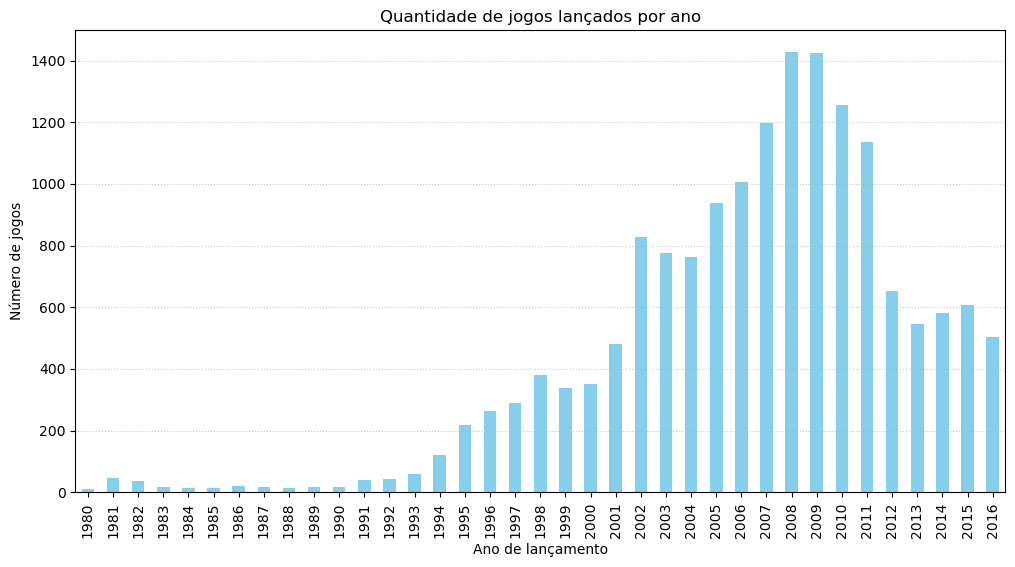

In [6]:
jogos_por_ano = df['year_of_release'].value_counts().sort_index()

print("Quantidade de jogos lançados por ano:")
print(jogos_por_ano)

plt.figure(figsize=(12, 6))
jogos_por_ano.plot(kind='bar', color='skyblue')
plt.title('Quantidade de jogos lançados por ano')
plt.xlabel('Ano de lançamento')
plt.ylabel('Número de jogos')
plt.grid(axis='y', linestyle=':', alpha=0.7)
plt.show()

Os dados de períodos muito antigos, como as décadas de 1980, 1990 ou o começo dos anos 2000, não são significativos para o objetivo atual de prever o sucesso de vendas para 2017. O mercado de games se transforma rapidamente, de modo que analisar o desempenho comercial do Atari ou do primeiro PlayStation traz poucos insights práticos para planejar campanhas voltadas a consoles modernos como o PS4 e Xbox One. Portanto, para a construção de modelos preditivos e análises de tendências atuais, o ideal é focar exclusivamente nos dados dos anos mais recentes.

Top 6 plataformas líderes de vendas totais ($ Milhões):
platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
Name: total_sales, dtype: float64


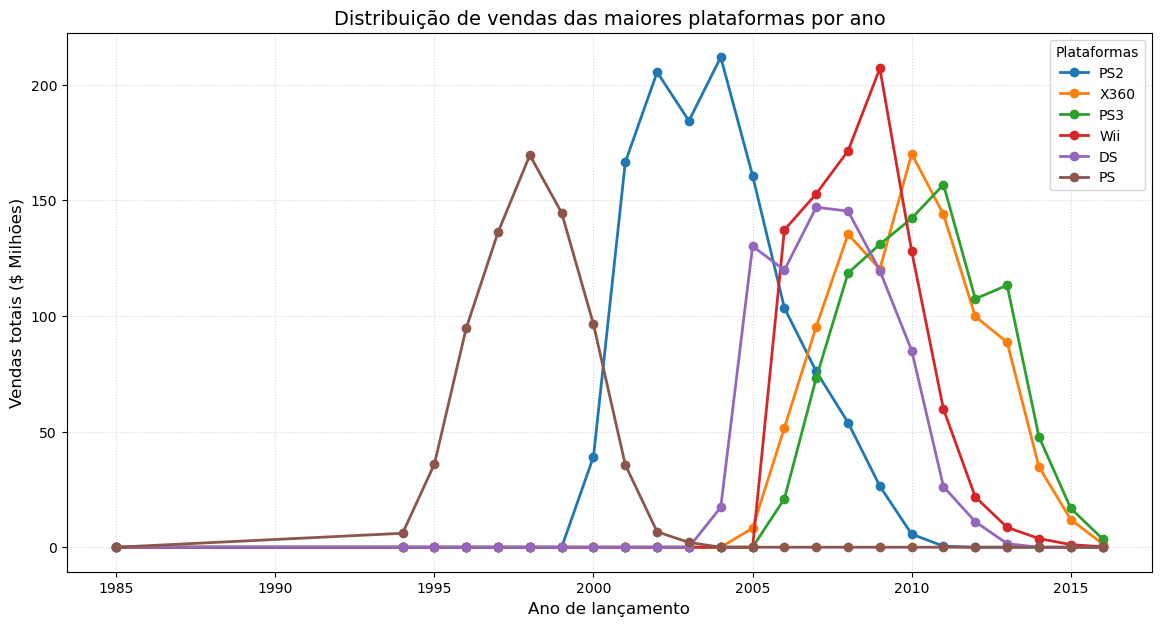

In [7]:
platform_sales = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print("Top 6 plataformas líderes de vendas totais ($ Milhões):")
print(platform_sales.head(6))

top_platforms = platform_sales.head(6).index.tolist()
yearly_sales = df[df['platform'].isin(top_platforms)].pivot_table(
    index='year_of_release', 
    columns='platform', 
    values='total_sales', 
    aggfunc='sum'
).fillna(0)

plt.figure(figsize=(14, 7))
for platform in top_platforms:
    plt.plot(yearly_sales.index, yearly_sales[platform], marker='o', label=platform, linewidth=2)

plt.title('Distribuição de vendas das maiores plataformas por ano', fontsize=14)
plt.xlabel('Ano de lançamento', fontsize=12)
plt.ylabel('Vendas totais ($ Milhões)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(title='Plataformas')
plt.show()

O ciclo de vida médio de uma plataforma de sucesso dura aproximadamente de 8 a 10 anos. A partir do seu lançamento, um console leva cerca de 3 a 5 anos para atingir o seu pico máximo de vendas globais, período no qual a base de usuários se consolida. O declínio definitivo e o desaparecimento do mercado ocorrem logo após a chegada dos consoles da próxima geração; nesse cenário de transição, as plataformas antigas levam cerca de 3 anos para que suas vendas remanescentes nas prateleiras sejam totalmente zeradas.  
Se o ciclo de vida dura cerca de 10 anos e as plataformas líderes do passado (PS3, X360) já estão morrendo em 2016, não faz sentido usá-las para nossa campanha de 2017. Portanto o foco será nas plataformas mais novas que surgiram por volta de 2013 e estão no topo do seu ciclo de vida atual.

In [8]:
df_relevante = df[df['year_of_release'] >= 2013].copy()

print(f"Número de registros antes do filtro: {len(df)}")
print(f"Número de registros no período relevante (2013-2016): {len(df_relevante)}")
display(df_relevante.head())

Número de registros antes do filtro: 16713
Número de registros no período relevante (2013-2016): 2233


,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
16,Grand Theft Auto V,PS3,2013,Action,7.02,9.09,0.98,3.96,97.0,8.2,M,21.05
23,Grand Theft Auto V,X360,2013,Action,9.66,5.14,0.06,1.41,97.0,8.1,M,16.27
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,NaN,NaN,Unknown,14.63
33,Pokemon X/Pokemon Y,3DS,2013,Role-Playing,5.28,4.19,4.35,0.78,NaN,NaN,Unknown,14.60
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97.0,8.3,M,12.62


year_of_release,2013,2014,2015,2016,total_periodo
platform,,,,,
PS4,25.99,100.00,118.90,69.25,314.14
PS3,113.25,47.76,16.82,3.60,181.43
XOne,18.96,54.07,60.14,26.15,159.32
3DS,56.57,43.76,27.78,15.14,143.25
X360,88.58,34.74,11.96,1.52,136.80
WiiU,21.65,22.03,16.35,4.60,64.63
PC,12.38,13.28,8.52,5.25,39.43
PSV,10.59,11.90,6.25,4.25,32.99
Wii,8.59,3.75,1.14,0.18,13.66


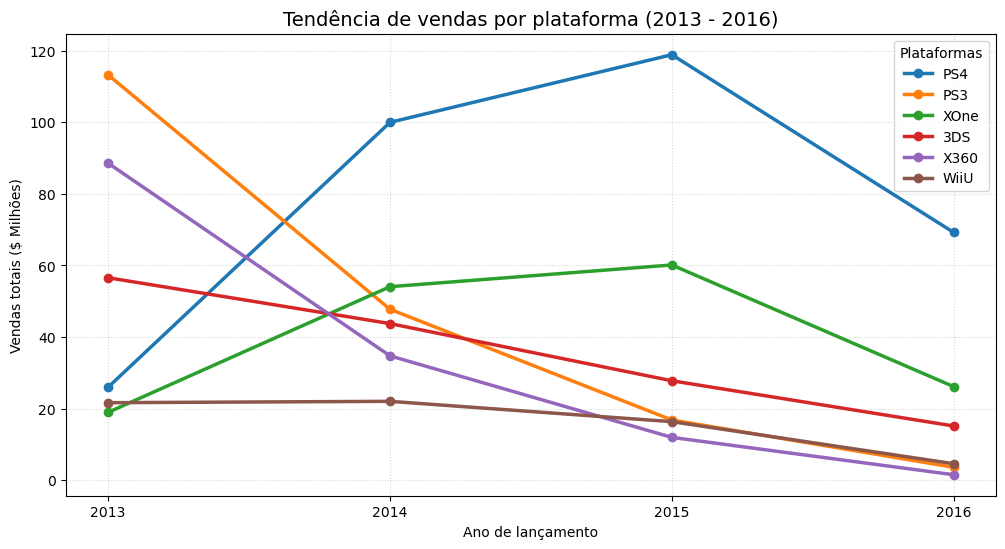

In [9]:
plataformas_vendas = df_relevante.pivot_table(
    index='platform', 
    columns='year_of_release', 
    values='total_sales', 
    aggfunc='sum'
).fillna(0)

plataformas_vendas['total_periodo'] = plataformas_vendas.sum(axis=1)
plataformas_vendas = plataformas_vendas.sort_values(by='total_periodo', ascending=False)
display(plataformas_vendas)

plt.figure(figsize=(12, 6))
top_atuais = plataformas_vendas.index[:6]

for platform in top_atuais:
    anos = [2013, 2014, 2015, 2016]
    vendas = plataformas_vendas.loc[platform, anos]
    plt.plot(anos, vendas, marker='o', label=platform, linewidth=2.5)

plt.title('Tendência de vendas por plataforma (2013 - 2016)', fontsize=14)
plt.xlabel('Ano de lançamento')
plt.ylabel('Vendas totais ($ Milhões)')
plt.xticks(anos)
plt.grid(True, linestyle=':', alpha=0.5)
plt.legend(title='Plataformas')
plt.show()

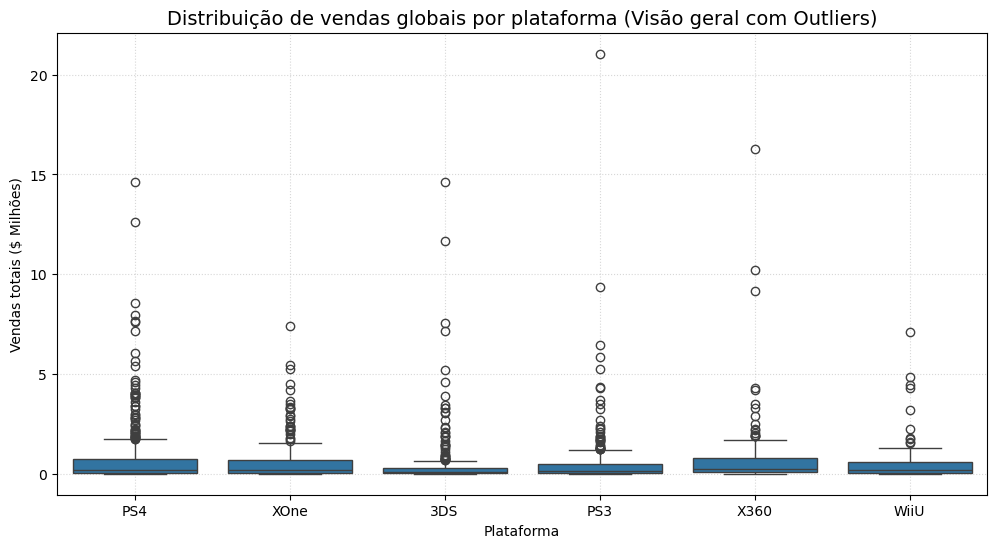

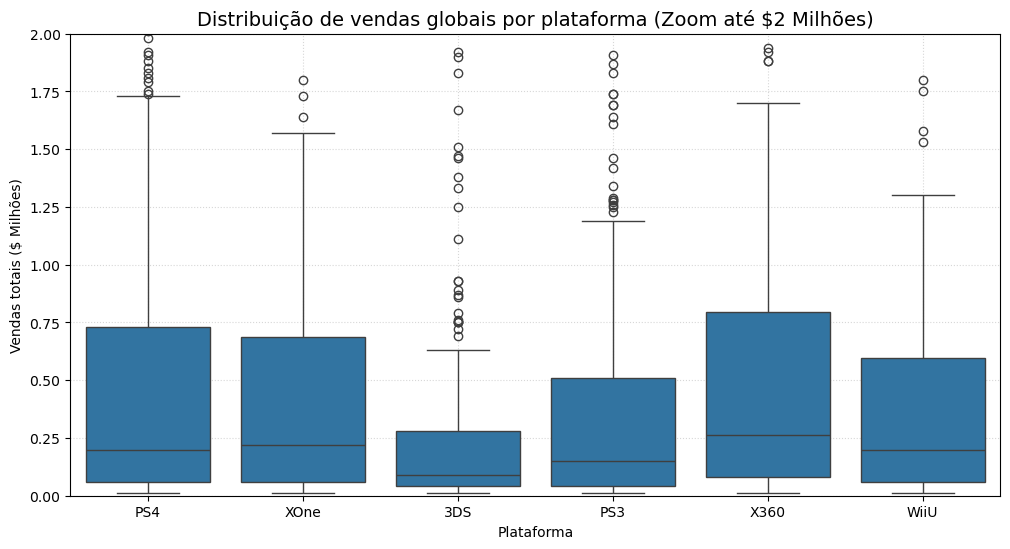

Média e Mediana de vendas por plataforma (2013-2016):


,mean,median,sum
platform,,,
3DS,0.472772,0.090,143.25
PS3,0.525884,0.150,181.43
PS4,0.801378,0.200,314.14
WiiU,0.562000,0.200,64.63
X360,0.735484,0.265,136.80
XOne,0.645020,0.220,159.32


In [10]:
plataformas_foco = ['PS4', 'XOne', '3DS', 'PS3', 'X360', 'WiiU']
df_filtrado_box = df_relevante[df_relevante['platform'].isin(plataformas_foco)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='platform', y='total_sales', data=df_filtrado_box, order=plataformas_foco)
plt.title('Distribuição de vendas globais por plataforma (Visão geral com Outliers)', fontsize=14)
plt.xlabel('Plataforma')
plt.ylabel('Vendas totais ($ Milhões)')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

plt.figure(figsize=(12, 6))
sns.boxplot(x='platform', y='total_sales', data=df_filtrado_box, order=plataformas_foco)
plt.ylim(0, 2)
plt.title('Distribuição de vendas globais por plataforma (Zoom até $2 Milhões)', fontsize=14)
plt.xlabel('Plataforma')
plt.ylabel('Vendas totais ($ Milhões)')
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()

print("Média e Mediana de vendas por plataforma (2013-2016):")
display(df_filtrado_box.groupby('platform')['total_sales'].agg(['mean', 'median', 'sum']))

As diferenças de vendas entre as plataformas são altamente significativas e revelam que a indústria de games é dominada por extremos. O gráfico geral exibe uma quantidade massiva de outliers (jogos que superam a marca de 5 a 10 milhões de cópias). Esse comportamento demonstra que, enquanto a vasta maioria dos títulos vende muito pouco e permanece concentrada na base do gráfico, um grupo seleto de sucessos estrondosos é responsável pela maior parte do faturamento de cada console.  
Ao analisar o "zoom" nas vendas médias e medianas, observam-se padrões claros entre os ecossistemas:  
Líderes de Consoles de Mesa (X360, XOne, PS4, WiiU): As medianas dessas plataformas são muito próximas (variando entre 0.20M e 0.26M), indicando que o comportamento comercial de um jogo padrão nesses consoles é bastante similar e mantém um piso de vendas firme.  
Média vs. Mediana: Em todas as plataformas, a média é expressivamente maior do que a mediana (como no PS4, com média de 0.80M contra mediana de 0.20M). Essa distorção ocorre porque a média é inflacionada pelos outliers gigantescos, enquanto a mediana reflete com maior fidelidade a realidade do jogo comum.  
O Caso do Nintendo 3DS: O portátil apresenta uma mediana muito mais baixa (0.09M) e caixa achatada. Isso se deve ao seu catálogo repleto de jogos de nicho e títulos exclusivos regionais focados no mercado japonês, que registram volumes baixos de vendas globais.

Xbox One - Correlação entre a nota dos críticos e as vendas: 0.42
Xbox One - Correlação entre a nota dos usuários e as vendas: -0.07


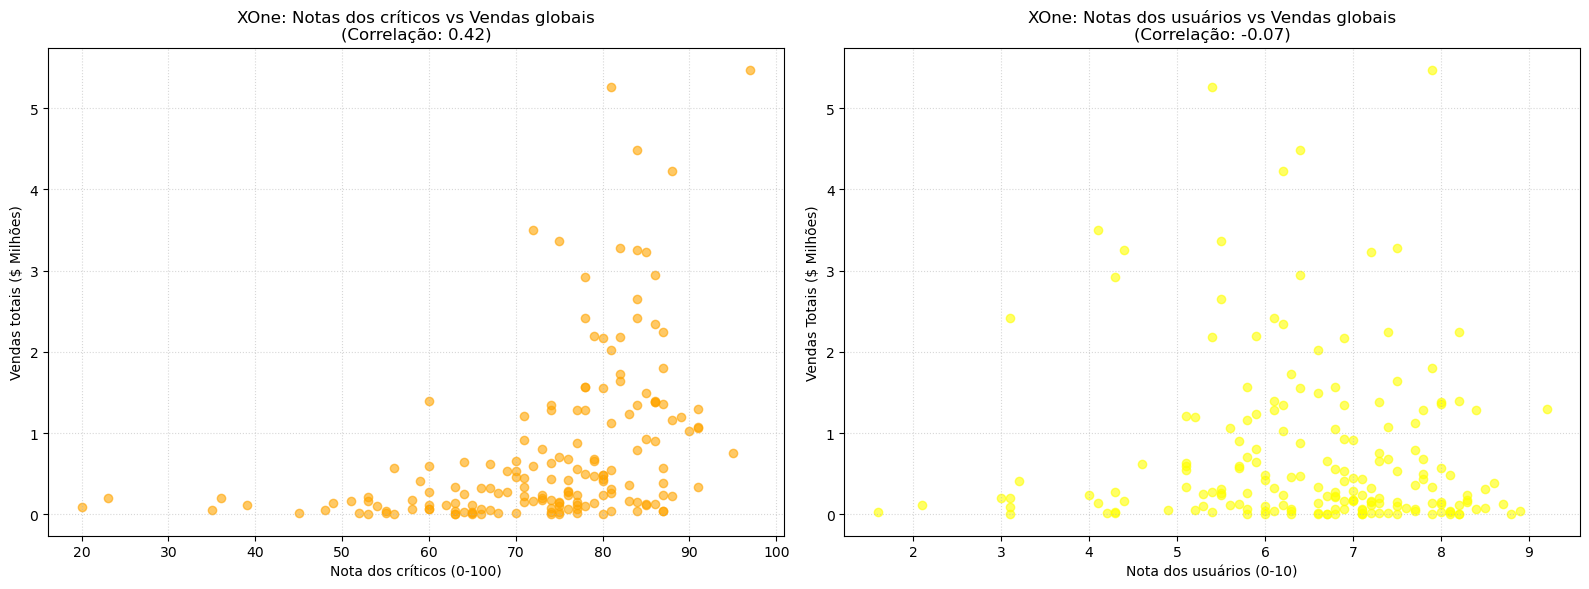

In [11]:
df_xone = df_relevante[df_relevante['platform'] == 'XOne']
corr_criticos_xone = df_xone['critic_score'].corr(df_xone['total_sales'])
corr_usuarios_xone = df_xone['user_score'].corr(df_xone['total_sales'])

print(f"Xbox One - Correlação entre a nota dos críticos e as vendas: {corr_criticos_xone:.2f}")
print(f"Xbox One - Correlação entre a nota dos usuários e as vendas: {corr_usuarios_xone:.2f}")

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
plt.scatter(df_xone['critic_score'], df_xone['total_sales'], alpha=0.6, color='orange')
plt.title(f'XOne: Notas dos críticos vs Vendas globais\n(Correlação: {corr_criticos_xone:.2f})')
plt.xlabel('Nota dos críticos (0-100)')
plt.ylabel('Vendas totais ($ Milhões)')
plt.grid(True, linestyle=':', alpha=0.5)

# Gráfico para Avaliação dos Usuários (XOne)
plt.subplot(1, 2, 2)
plt.scatter(df_xone['user_score'], df_xone['total_sales'], alpha=0.6, color='yellow')
plt.title(f'XOne: Notas dos usuários vs Vendas globais\n(Correlação: {corr_usuarios_xone:.2f})')
plt.xlabel('Nota dos usuários (0-10)')
plt.ylabel('Vendas Totais ($ Milhões)')
plt.grid(True, linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

In [12]:
df_consoles = df_relevante[df_relevante['platform'].isin(['PS4', 'XOne'])]

jogos_compartilhados = df_consoles.groupby('name').filter(lambda x: len(x['platform'].unique()) == 2)
comparacao_vendas = jogos_compartilhados.groupby('platform')['total_sales'].agg(['sum', 'mean', 'count'])

print("Comparação de vendas globais dos mesmos jogos:")
display(comparacao_vendas)

Comparação de vendas globais dos mesmos jogos:


,sum,mean,count
platform,,,
PS4,256.35,1.181336,217
XOne,129.36,0.596129,217


Métricas de vendas por gênero:


,count,sum,mean,median
genre,,,,
Action,766,321.87,0.420196,0.110
Shooter,187,232.98,1.245882,0.450
Sports,214,150.65,0.703972,0.240
Role-Playing,292,145.89,0.499623,0.125
Misc,155,62.82,0.405290,0.100
Platform,74,42.63,0.576081,0.225
Racing,85,39.89,0.469294,0.120
Fighting,80,35.31,0.441375,0.125
Adventure,245,23.64,0.096490,0.030


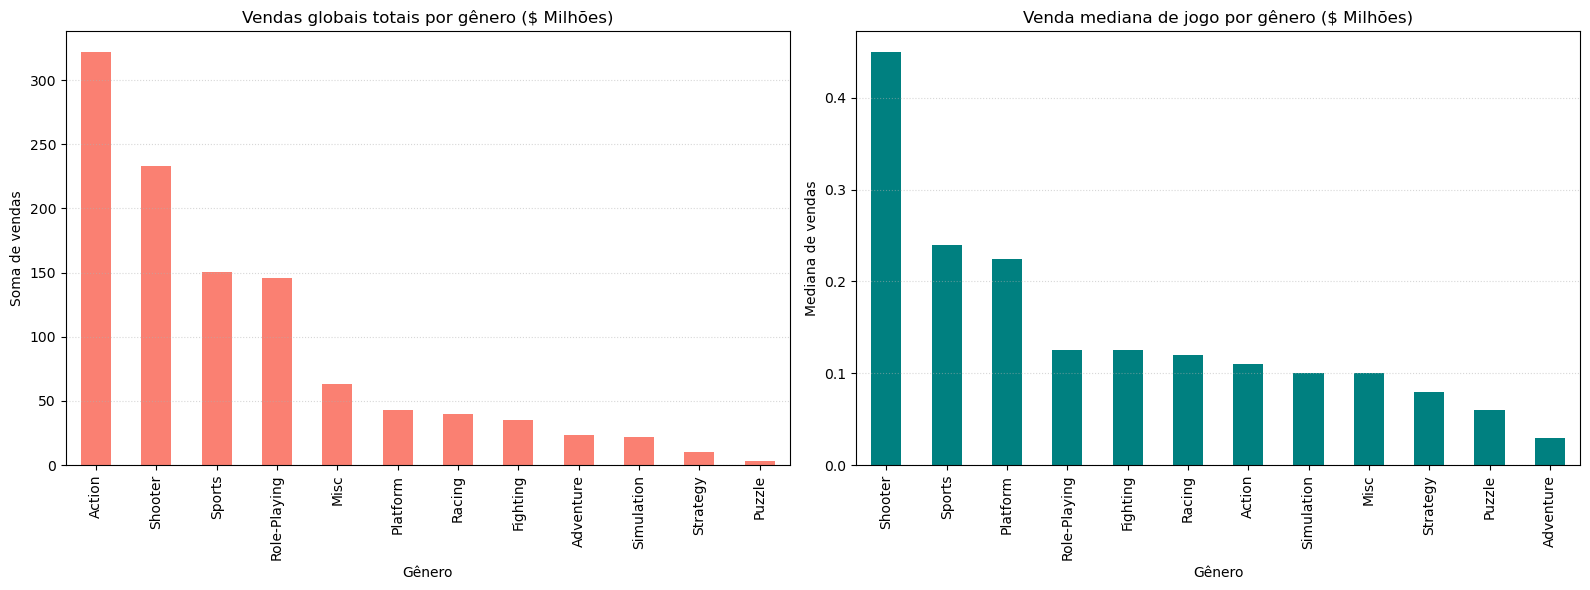

In [13]:
generos_analise = df_relevante.groupby('genre')['total_sales'].agg(['count', 'sum', 'mean', 'median']).sort_values(by='sum', ascending=False)

print("Métricas de vendas por gênero:")
display(generos_analise)

plt.figure(figsize=(16, 6))

plt.subplot(1, 2, 1)
generos_analise['sum'].plot(kind='bar', color='salmon')
plt.title('Vendas globais totais por gênero ($ Milhões)')
plt.xlabel('Gênero')
plt.ylabel('Soma de vendas')
plt.grid(axis='y', linestyle=':', alpha=0.5)

generos_ordenados_mediana = generos_analise.sort_values(by='median', ascending=False)
plt.subplot(1, 2, 2)
generos_ordenados_mediana['median'].plot(kind='bar', color='teal')
plt.title('Venda mediana de jogo por gênero ($ Milhões)')
plt.xlabel('Gênero')
plt.ylabel('Mediana de vendas')
plt.grid(axis='y', linestyle=':', alpha=0.5)

plt.tight_layout()
plt.show()

Olhar apenas para o faturamento total gera a "Ilusão do Gênero Ação", embora lidere em vendas totais (321M), o gênero possui uma quantidade massiva de títulos (766), resultando em uma mediana baixíssima (0.11M). Seu sucesso financeiro depende de poucos blockbusters. O verdadeiro campeão comercial é o gênero Shooter: vice-líder em vendas totais (232M) com apenas 187 jogos, ostenta a maior mediana do mercado (0.45M), provando que um jogo de tiro comum é muito mais rentável e estável.  
O mercado divide-se claramente em três patamares de desempenho:  
Vendas Altas (Shooter e Sports): Altamente consistentes, com médias e medianas elevadas. Atraem o público de massa que consome franquias anuais, representando investimentos seguros.  
Vendas Médias (Platform e RPG): Sustentados por comunidades fiéis e grandes franquias exclusivas, mantendo vendas saudáveis.  
Vendas Baixas (Adventure, Strategy e Puzzle): Títulos de nicho focados em história ou raciocínio. Possuem baixo apelo comercial de massa e faturamento reduzido (ex: Adventure tem mediana de apenas 0.03M).  
Recomendação para 2017: Concentrar os esforços de marketing em Shooter e Sports para garantir alto volume de vendas por título. Para o gênero Action, o foco publicitário deve ser restrito exclusivamente aos grandes lançamentos (outliers de peso).

## Etapa 4. Crie um perfil de usuário para cada região

--- TOP 5 PLATAFORMAS: AMÉRICA DO NORTE ---


platform
PS4     24.842933
XOne    21.274360
X360    18.656188
PS3     14.507322
3DS      8.727239
Name: na_sales, dtype: float64


--- TOP 5 PLATAFORMAS: EUROPA ---


platform
PS4     35.971241
PS3     17.288326
XOne    13.152997
X360    10.840578
3DS      7.893328
Name: eu_sales, dtype: float64


--- TOP 5 PLATAFORMAS: JAPÃO ---


platform
3DS     48.167353
PS3     16.586163
PSV     13.205001
PS4     11.336838
WiiU     7.728371
Name: jp_sales, dtype: float64

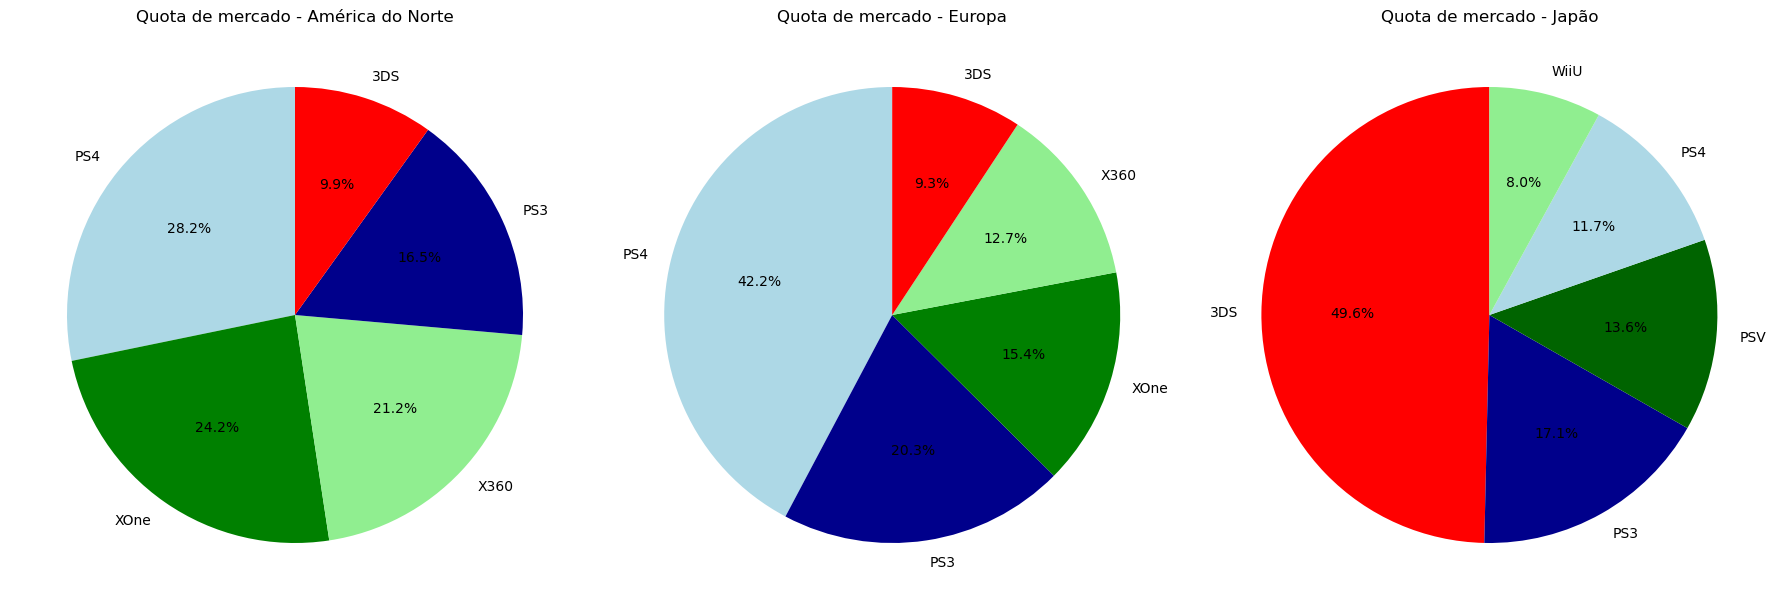

In [14]:
total_na = df_relevante['na_sales'].sum()
total_eu = df_relevante['eu_sales'].sum()
total_jp = df_relevante['jp_sales'].sum()

top5_na = df_relevante.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head(5)
top5_eu = df_relevante.groupby('platform')['eu_sales'].sum().sort_values(ascending=False).head(5)
top5_jp = df_relevante.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head(5)

share_na = (top5_na / total_na) * 100
share_eu = (top5_eu / total_eu) * 100
share_jp = (top5_jp / total_jp) * 100

print("--- TOP 5 PLATAFORMAS: AMÉRICA DO NORTE ---")
display(share_na)

print("\n--- TOP 5 PLATAFORMAS: EUROPA ---")
display(share_eu)

print("\n--- TOP 5 PLATAFORMAS: JAPÃO ---")
display(share_jp)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].pie(share_na, labels=share_na.index, autopct='%1.1f%%', startangle=90, colors=['lightblue', 'green', 'lightgreen', 'darkblue', 'red'])
axes[0].set_title('Quota de mercado - América do Norte')

axes[1].pie(share_eu, labels=share_eu.index, autopct='%1.1f%%', startangle=90, colors=['lightblue', 'darkblue', 'green', 'lightgreen', 'red'])
axes[1].set_title('Quota de mercado - Europa')

axes[2].pie(share_jp, labels=share_jp.index, autopct='%1.1f%%', startangle=90, colors=['red', 'darkblue', 'darkgreen', 'lightblue', 'lightgreen'])
axes[2].set_title('Quota de mercado - Japão')

plt.tight_layout()
plt.show()

In [15]:
top5_generos_na = df_relevante.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head(5)
top5_generos_eu = df_relevante.groupby('genre')['eu_sales'].sum().sort_values(ascending=False).head(5)
top5_generos_jp = df_relevante.groupby('genre')['jp_sales'].sum().sort_values(ascending=False).head(5)

print("--- TOP 5 GÊNEROS: AMÉRICA DO NORTE ---")
print(top5_generos_na)

print("\n--- TOP 5 GÊNEROS: EUROPA ---")
print(top5_generos_eu)

print("\n--- TOP 5 GÊNEROS: JAPÃO ---")
print(top5_generos_jp)

--- TOP 5 GÊNEROS: AMÉRICA DO NORTE ---
genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64

--- TOP 5 GÊNEROS: EUROPA ---
genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64

--- TOP 5 GÊNEROS: JAPÃO ---
genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64


A América do Norte (AN) e a Europa (UE) apresentam perfis quase idênticos. Action e Shooter dominam o topo, refletindo a preferência ocidental por jogos acelerados e cinemáticos. Sports mantém o terceiro lugar em ambos (Madden/NBA na AN e FIFA na UE). A única divergência no Top 5 é que a AN consome mais jogos casuais (Misc), enquanto a UE prefere Racing.  
Já o Japão (JP) quebra totalmente o padrão ocidental. Role-Playing (RPG) é o líder absoluto devido à forte preferência cultural por franquias locais (ex: Pokémon e Final Fantasy). O gênero Action fica em segundo, enquanto os Shooters despencam para a última posição com vendas minúsculas. Além disso, o gênero Fighting entra no Top 5 japonês, impulsionado pela cultura de jogos competitivos de luta.  
Portanto as campanhas de jogos de Tiro ou Esportes devem concentrar o orçamento na América do Norte e Europa. Já os lançamentos de RPG devem ter como foco principal de massa o mercado do Japão.

Vendas por classificação ESRB por região ($ Milhões):


,na_sales,eu_sales,jp_sales
rating,,,
E,79.05,83.36,15.14
E10+,54.24,42.69,5.89
M,165.21,145.32,14.11
T,49.79,41.95,20.59
Unknown,89.42,78.91,85.05


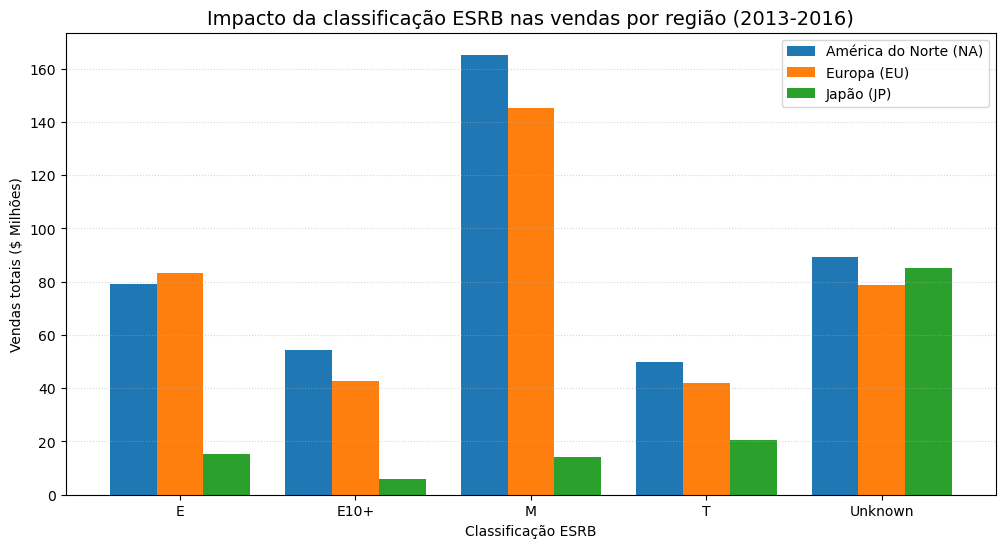

In [16]:
esrb_vendas = df_relevante.groupby('rating')[['na_sales', 'eu_sales', 'jp_sales']].sum()

print("Vendas por classificação ESRB por região ($ Milhões):")
display(esrb_vendas)

esrb_vendas.plot(kind='bar', figsize=(12, 6), width=0.8)
plt.title('Impacto da classificação ESRB nas vendas por região (2013-2016)', fontsize=14)
plt.xlabel('Classificação ESRB')
plt.ylabel('Vendas totais ($ Milhões)')
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.legend(['América do Norte (NA)', 'Europa (EU)', 'Japão (JP)'])
plt.show()

Impacto das Classificações ESRB nas Vendas Regionais:  
América do Norte (NA) e Europa (EU): O comportamento é idêntico e dominado pela categoria M (Mature), líder absoluta de faturamento por englobar os maiores blockbusters ocidentais. A categoria E (Everyone) aparece em segundo lugar, impulsionada por franquias de esportes e jogos casuais.  
Japão (JP): O padrão se inverte. A classificação M vende pouquíssimo, enquanto a categoria 'Unknown' (Desconhecida) lidera de forma isolada (~85M). Isso ocorre porque o ESRB é um órgão americano, e o mercado nipônico utiliza um sistema próprio (CERO). Logo, a etiqueta 'Unknown' concentra os jogos de sucesso puramente japoneses (como Pokémon e RPGs locais) que não passaram pelo crivo dos EUA.  
Estratégia de Marketing para 2017: No Ocidente, a aposta mais segura e lucrativa são os jogos de classificação M. No Japão, o foco deve ser em títulos E, T (Teen) ou em produções de estúdios locais (os 'Unknown'), já que o público oriental rejeita a maior parte dos jogos maduros ocidentais.

## Etapa 5. Teste as seguintes hipóteses:

In [17]:
from scipy import stats

scores_xone = df_relevante[(df_relevante['platform'] == 'XOne') & (df_relevante['user_score'].notna())]['user_score']
scores_pc = df_relevante[(df_relevante['platform'] == 'PC') & (df_relevante['user_score'].notna())]['user_score']

print(f"Nota média dos usuários no Xbox One: {scores_xone.mean():.2f}")
print(f"Nota média dos usuários no PC: {scores_pc.mean():.2f}")
print("-" * 50)

alpha = 0.05
results = stats.ttest_ind(scores_xone, scores_pc, equal_var=False)
print(f"Valor-p (p-value): {results.pvalue}")

if results.pvalue < alpha:
    print("Resultado: Rejeitamos a hipótese nula.")
    print("Conclusão: As classificações médias dos usuários das plataformas Xbox One e PC são diferentes.")
else:
    print("Resultado: Não podemos rejeitar a hipótese nula.")
    print("Conclusão: Não há evidência estatística de que as classificações médias dos usuários sejam diferentes.")

Nota média dos usuários no Xbox One: 6.52
Nota média dos usuários no PC: 6.27
--------------------------------------------------
Valor-p (p-value): 0.14759594013430463
Resultado: Não podemos rejeitar a hipótese nula.
Conclusão: Não há evidência estatística de que as classificações médias dos usuários sejam diferentes.


In [18]:
notas_action = df_relevante[(df_relevante['genre'] == 'Action') & (df_relevante['user_score'].notna())]['user_score']
notas_sports = df_relevante[(df_relevante['genre'] == 'Sports') & (df_relevante['user_score'].notna())]['user_score']

print(f"Média das notas dos usuários para o gênero Action: {notas_action.mean():.2f}")
print(f"Média das notas dos usuários para o gênero Sports: {notas_sports.mean():.2f}")
print("-" * 50)

alpha = 0.05
results_genero = stats.ttest_ind(notas_action, notas_sports, equal_var=False)

print(f"Valor-p (p-value): {results_genero.pvalue}")

if results_genero.pvalue < alpha:
    print("Rejeitamos a hipótese nula (H0).")
    print("Conclusão: As classificações médias de usuários para os gêneros Action e Sports são estatisticamente diferentes.")
else:
    print("Não podemos rejeitar a hipótese nula (H0).")
    print("Conclusão: Não há evidência estatística de diferença entre as médias.")

Média das notas dos usuários para o gênero Action: 6.84
Média das notas dos usuários para o gênero Sports: 5.24
--------------------------------------------------
Valor-p (p-value): 1.4460039700704315e-20
Rejeitamos a hipótese nula (H0).
Conclusão: As classificações médias de usuários para os gêneros Action e Sports são estatisticamente diferentes.


Hipótese Nula ($H_0$)É o ponto de partida conservador do teste. Ela assume o princípio do ceticismo, afirmando que não existe diferença real entre os grupos analisados e que qualquer variação encontrada nos dados é mero fruto do acaso (ruído da amostra).  
Plataformas: $H_0: \mu_{\text{XOne}} = \mu_{\text{PC}}$ (As notas médias são iguais).  
Gêneros: $H_0: \mu_{\text{Action}} = \mu_{\text{Sports}}$ (As notas médias são iguais).  
Hipótese Alternativa ($H_1$)É a afirmação que o projeto busca testar e tentar provar. Ela contradiz diretamente a hipótese nula, sustentando que existe uma diferença estatisticamente significativa entre as médias e que o fator analisado (seja a plataforma ou o gênero) realmente influencia a opinião dos usuários. Como buscávamos apenas identificar se os grupos divergiam, as hipóteses foram formuladas de maneira bilateral (diferente de).  
Plataformas: $H_1: \mu_{\text{XOne}} \neq \mu_{\text{PC}}$ (As notas médias são diferentes).  
Gêneros: $H_1: \mu_{\text{Action}} \neq \mu_{\text{Sports}}$ (As notas médias são diferentes).  
O teste estatístico calcula o valor-p para medir a probabilidade de a hipótese nula ser verdadeira. Ao compará-lo com o limiar alfa ($\alpha = 0.05$), rejeitamos $H_0$ se o valor-p for menor que o limiar, validando a hipótese alternativa. Caso contrário, mantemos $H_0$ por falta de provas em contrário.

O nível de significância escolhido para os testes foi de $\alpha = 0,05$ (5%).  
O primeiro fator escolhido foi o padrão da indústria, porque o limite de 5% é o referencial mais adotado em análises de negócios e comportamento de mercado. Ele estabelece um critério rigoroso, mas realista, para validar decisões estratégicas.  
Já o segundo fator foi equilíbrio de erros pois esse percentual garante que o risco de cometer um Erro do Tipo I (rejeitar a hipótese nula quando ela é verdadeira) seja de no máximo 5%. Em termos práticos, há menos de 5% de chance de a loja afirmar que existe uma diferença real no mercado (como na preferência por um gênero de jogo) quando a variação não passa de mera coincidência ou ruído dos dados.  
Se o valor-p calculado for menor que 0,05, a hipótese nula é rejeitada; se for maior ou igual, ela é mantida por falta de evidências estatísticas em contrário.

## Etapa 6. Conclusão geral

### Conclusão e Diretrizes Estratégicas para 2017 (Período Base: 2013–2016)
Dinâmica de Plataformas: O PS4 e o Xbox One consolidaram-se como líderes de mercado. Como o ciclo de vida dos consoles atinge o ápice entre 3 e 5 anos antes de decair (como visto no PS3 e X360), o marketing para 2017 deve focar prioritariamente no PS4 e, de forma complementar, no Xbox One.  
Gêneros e Lucratividade: Embora Action lidere em faturamento total pelo volume massivo de títulos, o gênero Shooter é o mais rentável e estável por jogo (maiores médias e medianas). Gêneros como Strategy e Puzzle permanecem estagnados como nichos de baixo retorno.  
Avaliações e Classificação Etária: As notas da crítica especializada possuem correlação positiva moderada (~0.42) com as vendas, sendo um indicador confiável para previsões, enquanto as notas dos usuários não demonstram impacto comercial. No Ocidente, jogos com classificação M (Mature) dominam amplamente o faturamento.  
Perfil Regional de Consumo:  
América do Norte: Mercado equilibrado entre PS4 e Xbox One, focado em Action, Shooter e Sports (classificação M).  
Europa: Hegemonia absoluta do PS4, seguindo as mesmas preferências de gênero e classificação da América do Norte.  
Japão: Cenário inverso ao ocidental. Rejeita consoles de mesa e Shooters, sendo dominado por portáteis (3DS e PS Vita) e pelo gênero RPG, com forte apelo para jogos locais sem o selo americano ESRB.  
Validação Estatística ($\alpha = 0.05$):Os testes de hipótese confirmaram que as notas dos usuários entre Xbox One e PC são equivalentes ($p\text{-value} \approx 0.14$).Por outro lado, a satisfação dos usuários entre os gêneros Action e Sports é significativamente diferente ($p\text{-value} \approx 0$), com vantagem para os jogos de ação.  
Com estas diretrizes baseadas em dados, a loja Ice está cientificamente respaldada para otimizar estoques e personalizar seus investimentos em marketing regional para 2017.